**IMPLEMENTACIÓN MODELO YOLO26m PARA DETECCIÓN**

In [1]:
from ultralytics import YOLO

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:
import numpy as np
import pandas as pd
import json

In [10]:
from tqdm import tqdm
import os
from pathlib import Path
from PIL import Image
import time
from IPython.display import clear_output

In [11]:
import cv2
import ast

**IMPLEMENTACIÓN DE FUNCIÓN PARA VALIDACIÓN DE FONDO EN IMAGENES**

In [12]:
def detectar_fotos(modelos, data, conf, salida):
    salida = Path(salida)
    salida.parent.mkdir(parents=True, exist_ok=True)

    if salida.exists():
        evaluados = pd.read_csv(salida)['modelo'].unique()
        modelos = [m for m in modelos if m not in evaluados]

    for model_name in tqdm(modelos, total=len(modelos)):
        model = YOLO(model_name + '.pt')

        res = model.val(data=data, classes=[15], conf=conf,
                        device=0, verbose=False)
    
        fila = pd.DataFrame([{'modelo': model_name, 'conf': conf,
                              'precision': res.box.mp,
                              'recall': res.box.mr,
                              'mAP50': res.box.map50,
                              'mAP50-95': res.box.map}])
        
        fila.to_csv(salida, mode='a', index=False, header=not salida.exists())

    return pd.read_csv(salida)

In [13]:
models = [ 'yolo26l', 'yolo26m', 'yolo11m', 'yolov8m']

**VALIDACIÓN MUESTRA 300**

In [14]:
#VALIDACIÓN DE METRICAS YOLO26m VALIDACIÓN Cat-Dataset
df_det_muestra_300 = detectar_fotos(
    modelos=models, data='../data/external/muestra_300/muestra_300.yaml', conf=0.1,
    salida='../outputs/detector/metricas_muestra_300_conf01.csv'
)

0it [00:00, ?it/s]


**VALIDACIÓN CAT BREEDS**

In [15]:
def reescribir_labels(labels_dir, clase):
    for label in Path(labels_dir).glob('*.txt'):
        data = []
        # SE LEE EL ARCHIVO COMPLETO Y SE CIERRA ANTES DE ESCRIBIR
        with open(label, 'r') as f:
            for lines in f:
                if not lines.strip():
                    continue
                line = lines.split()
                line[0] = clase
                data.append(" ".join(str(n) for n in line))

        # SE SOBRESCRIBE EL MISMO ARCHIVO
        with open(label, 'w') as f:
            f.write("\n".join(data))

In [17]:
#reescribir_labels('../data/external/cats_val/labels', 15) 

In [20]:
#VALIDACIÓN DE METRICAS YOLO26m VALIDACIÓN Cat-Dataset
df_det_cat_breeds = detectar_fotos(
    modelos=models, data='../data/external/cats_val/data.yaml', conf=0.1,
    salida='../outputs/detector/metricas_cats_val_conf01.csv'
)

0it [00:00, ?it/s]


**ANALISIS SESGOS**

In [21]:
df_cat_breeds = pd.read_csv('../data/processed/detecction/analisis_cat_breeds.csv')
df_cat_breeds = df_cat_breeds[[
                'file_path', 'file_name', 'clase', 
                'cx', 'cy', 'w', 'h', 'raza']]

In [22]:
df_cat_breeds_prediction = pd.DataFrame({
    'file_path': df_cat_breeds['file_path'],
    'file_name': df_cat_breeds['file_name'],
    'class': df_cat_breeds['clase'],
    'raza': df_cat_breeds['raza'],
    'real_report': df_cat_breeds.apply(
        lambda row:
            [
                float(row['cx']), 
                float(row['cy']), 
                float(row['w']), 
                float(row['h']),
            ], axis=1
    ),
})

In [23]:
df_cat_breeds_prediction.head(2)

,file_path,file_name,class,raza,real_report
0,../data/external/cats_breeds/images/00a80980-a...,00a80980-a874-48ad-b569-6ca771a71f85_jpeg_jpg....,44,Selkirk Rex,"[0.34140625, 0.48203125, 0.63046875, 0.74453125]"
1,../data/external/cats_breeds/images/10895463_9...,10895463_920_jpg.rf.7da5102e26e93e0c2f71bf4976...,4,Balinese,"[0.53125, 0.45703125, 0.9375, 0.7203125]"


In [24]:
def report_inf(entry, models, output_path):
    paths = entry["file_path"].tolist()
    df_output = pd.read_csv(output_path) if os.path.exists(output_path) else None

    for model_name in models:
        col_coords = f"coordenadas_{model_name}"
        col_conf = f"conf_{model_name}"

        if col_coords in df_output.columns and col_conf in df_output.columns:
            entry[col_coords] = df_output[col_coords].values
            entry[col_conf] = df_output[col_conf].values
            continue

        model = YOLO(model_name + ".pt")
        coords_list, conf_list = [], []

        for path in tqdm(paths, desc=model_name):
            r = model.predict(path, classes=[15], conf=0.1, device=0, verbose=False)[0]

            if len(r.boxes) > 0:
                i = r.boxes.conf.argmax().item()
                coords_list.append(r.boxes.xyxy[i].tolist())
                conf_list.append(float(r.boxes.conf[i]))
            else:
                coords_list.append(None)
                conf_list.append(None)

        entry[f"coordenadas_{model_name}"] = coords_list
        entry[f"conf_{model_name}"] = conf_list

        entry.to_csv(
            output_path, index=False
        )

    return entry

In [25]:
result_report_inf = report_inf(df_cat_breeds_prediction, models, '../data/processed/detecction/analisis_breeds.csv')

In [26]:
result_report_inf.head(1)

,file_path,file_name,class,raza,real_report,coordenadas_yolo26l,conf_yolo26l,coordenadas_yolo26m,conf_yolo26m,coordenadas_yolo11m,conf_yolo11m,coordenadas_yolov8m,conf_yolov8m
0,../data/external/cats_breeds/images/00a80980-a...,00a80980-a874-48ad-b569-6ca771a71f85_jpeg_jpg....,44,Selkirk Rex,"[0.34140625, 0.48203125, 0.63046875, 0.74453125]","[21.244903564453125, 68.6650390625, 405.040008...",0.919434,"[19.273101806640625, 63.60130310058594, 405.00...",0.906373,"[19.709564208984375, 70.168212890625, 405.4903...",0.89129,"[19.032958984375, 70.13648986816406, 407.78469...",0.867093


In [27]:
cols_conf = result_report_inf.columns[result_report_inf.columns.str.startswith(('class', 'conf_'))]
analisis_cat_breeds_inf = result_report_inf[cols_conf].groupby(['class']).mean()

In [28]:
analisis_cat_breeds_inf.head()

,conf_yolo26l,conf_yolo26m,conf_yolo11m,conf_yolov8m
class,,,,
0,0.812815,0.816773,0.806731,0.792818
1,0.785408,0.796793,0.791591,0.750367
2,0.802429,0.827297,0.829332,0.793545
3,0.796969,0.830635,0.819949,0.760310
4,0.784814,0.764155,0.780761,0.737295


In [29]:
cols = ['raza', 'conf_yolo26l', 'conf_yolo26m', 'conf_yolo11m', 'conf_yolov8m']
analisis_tazas = result_report_inf[cols].groupby(['raza'])
total_por_clase = analisis_tazas.size()

tasa_deteccion = analisis_tazas.count().div(total_por_clase, axis=0)
tasa_deteccion.head(2)

,conf_yolo26l,conf_yolo26m,conf_yolo11m,conf_yolov8m
raza,,,,
Abyssianian,0.928571,0.939286,0.953571,0.967857
American Curl,0.961538,0.953846,0.969231,0.984615


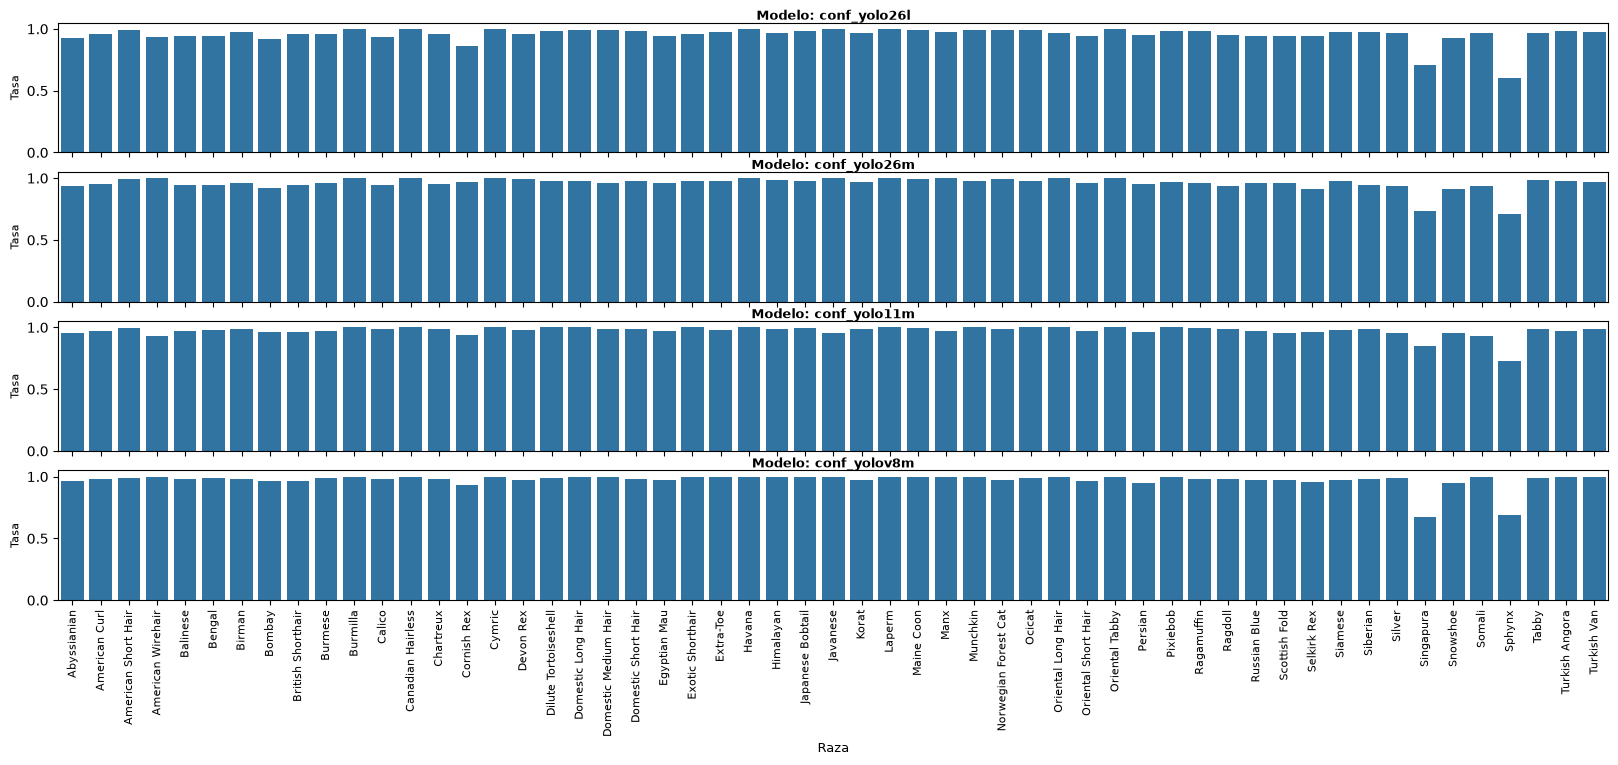

In [30]:
plt.figure(figsize=(20, 7.5))

for i, model in enumerate(tasa_deteccion.columns):
    ax = plt.subplot(4, 1, i+1)
    
    sns.barplot(data=tasa_deteccion, x=tasa_deteccion.index, y=model, ax=ax)

    ax.set_title(f"Modelo: {model}", fontsize=9, fontweight='bold', pad=2)
    ax.set_ylabel("Tasa", fontsize=8)

    if i == len(tasa_deteccion.columns) - 1:
        plt.xticks(rotation=90, fontsize=8)
        ax.set_xlabel("Raza", fontsize=9)
    else:
        ax.set_xticklabels([])
        ax.set_xlabel("")

plt.subplots_adjust(hspace=0.15, top=0.92, bottom=0.15)
plt.show()

**EVALUACIÓN DE MODELOS POR NIVELES DE CONFIANZA**

In [31]:
df_cat_breeds_prediction_analisis = df_cat_breeds_prediction.copy()

In [32]:
def yolo_to_xyxy(box, width, height):
    xc, yc, w, h = box

    x1 = (xc - w / 2) * width
    y1 = (yc - h / 2) * height
    x2 = (xc + w / 2) * width
    y2 = (yc + h / 2) * height

    return [x1, y1, x2, y2]

In [33]:
def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0

In [34]:
def parse_box(box):
    if isinstance(box, str):
        box = ast.literal_eval(box)

    if box is None or (isinstance(box, float) and np.isnan(box)):
        return None

    return [float(x) for x in box]

In [35]:

def evaluate_models(
    df,
    models,
    iou_threshold=0.5,
    confidence_thresholds=[0.2, 0.35, 0.5, 0.65, 0.8]
):

    results = []

    for model in models:

        col_coords = f'coordenadas_{model}'
        col_conf = f'conf_{model}'

        metrics = {
            threshold: {'TP': 0, 'FP': 0, 'FN': 0}
            for threshold in confidence_thresholds
        }

        for idx, row in df.iterrows():

            with Image.open(row['file_path']) as img:
                width, height = img.size

            real_data = parse_box(row['real_report'])
            pred_box = parse_box(row[col_coords])
            pred_conf = row[col_conf]

            real_box = yolo_to_xyxy(
                real_data[:4], width, height
            )

            if pd.isna(pred_conf):
                pred_conf = None
            else:
                pred_conf = float(pred_conf)

            iou = (
                calculate_iou(real_box, pred_box)
                if pred_box is not None else None
            )

            for threshold in confidence_thresholds:

                counts = metrics[threshold]

                if pred_box is None or pred_conf is None or pred_conf < threshold:
                    counts['FN'] += 1
                    continue

                if iou >= iou_threshold:
                    counts['TP'] += 1
                else:
                    counts['FP'] += 1
                    counts['FN'] += 1


        for threshold, counts in metrics.items():

            tp = counts['TP']
            fp = counts['FP']
            fn = counts['FN']

            precision = tp / (tp + fp) if tp + fp else 0
            recall = tp / (tp + fn) if tp + fn else 0

            f1 = (
                2 * precision * recall / (precision + recall)
                if precision + recall else 0
            )

            results.append({
                'model': model,
                'confidence_threshold': threshold,
                'TP': tp,
                'FP': fp,
                'FN': fn,
                'Precision': precision,
                'Recall': recall,
                'F1': f1
            })

    return pd.DataFrame(results)

In [36]:
result_analisis_iou = evaluate_models(df_cat_breeds_prediction_analisis, models)

In [39]:
result_analisis_iou.head()

,model,confidence_threshold,TP,FP,FN,Precision,Recall,F1
0,yolo26l,0.20,6822,201,622,0.971380,0.916443,0.943112
1,yolo26l,0.35,6685,170,759,0.975201,0.898039,0.935030
2,yolo26l,0.50,6397,133,1047,0.979632,0.859350,0.915557
3,yolo26l,0.65,5853,92,1591,0.984525,0.786271,0.874300
4,yolo26l,0.80,4729,40,2715,0.991612,0.635277,0.774421


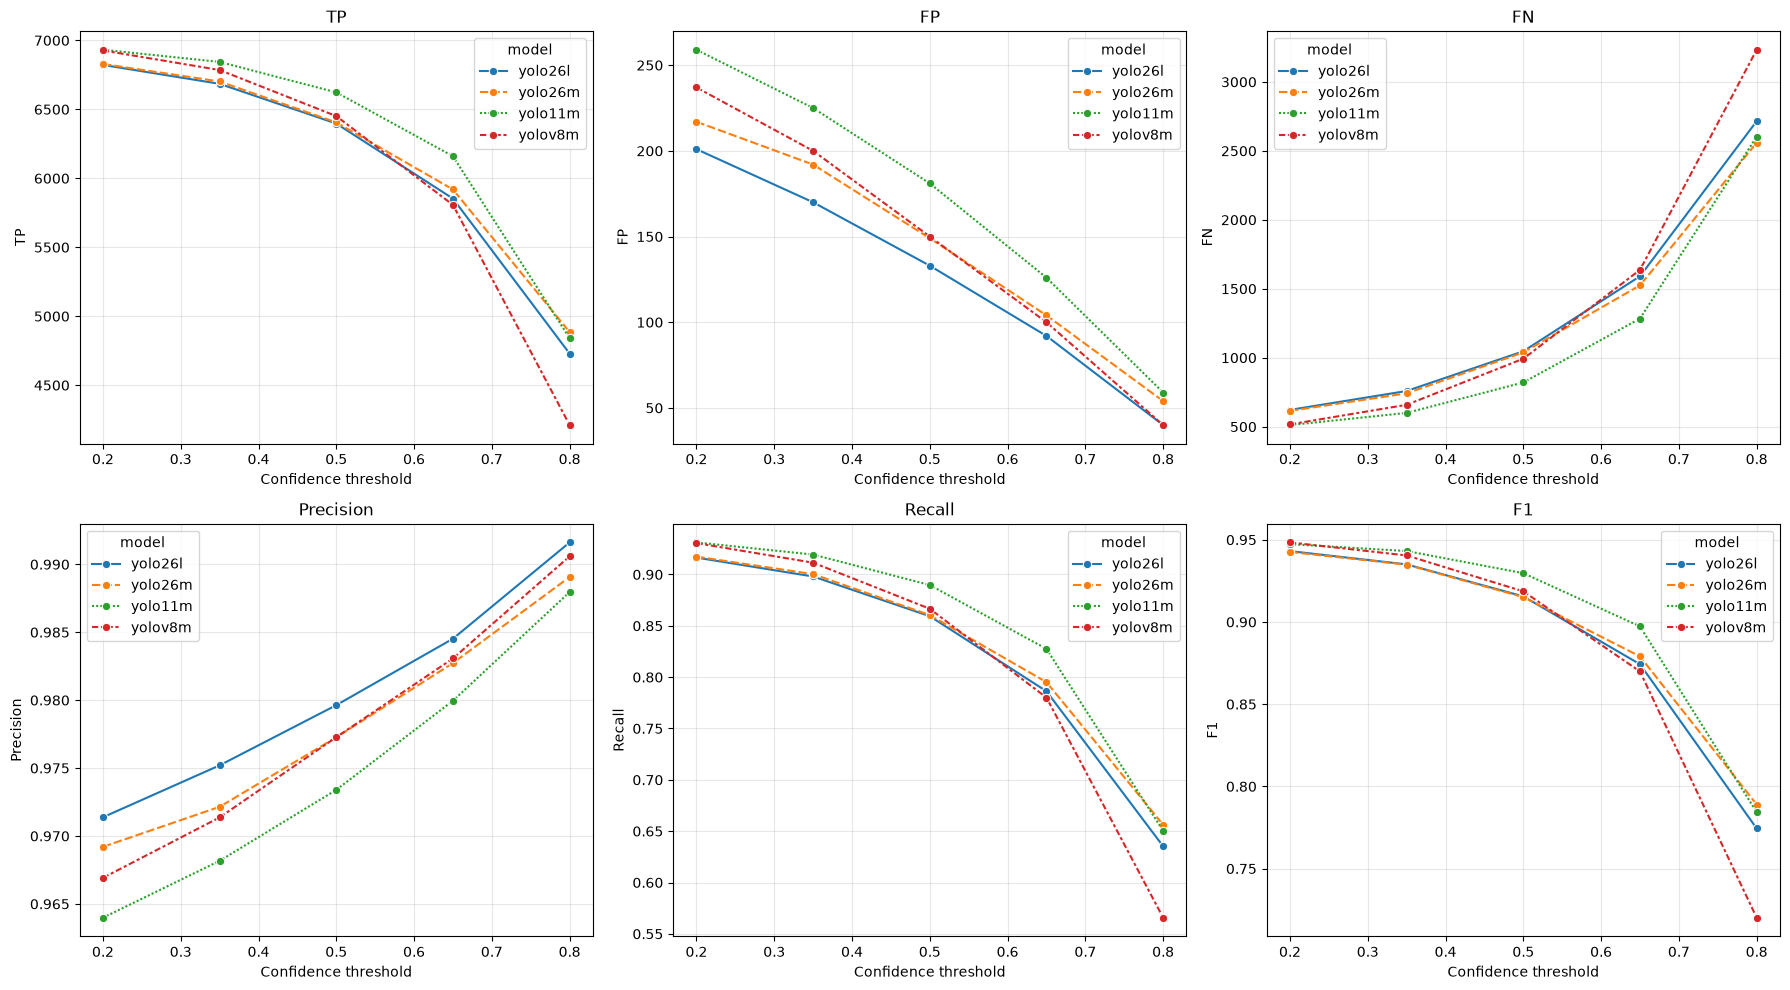

In [40]:
metrics = ['TP', 'FP', 'FN', 'Precision', 'Recall', 'F1']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, metric in zip(axes.flat, metrics):

    sns.lineplot(
        data=result_analisis_iou,
        x='confidence_threshold',
        y=metric,
        hue='model',
        marker='o',
        ax=ax,
        style='model'
    )

    ax.set_title(metric)
    ax.set_xlabel('Confidence threshold')
    ax.set_ylabel(metric)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**ANALISIS RECORTE IMAGENES REID**

In [41]:
df_reid = pd.read_csv('../data/processed/df_cat_reid.csv')
df_reid_modified = df_reid.copy()

**VALIDACIÓN CANTIDAD DE REGISTROS EN EL DATASET ORIGINAL**

In [42]:
len(df_reid_modified)

13106

In [43]:
df_reid_modified.head()

,file_path,dir_name,file_name,format,resolution,ratio,mode,file_size_mb,brightness
0,../data/interim/reid_cat/0001/0001_000.JPG,1,0001_000,JPEG,7990272,1.33,RGB,0.795949,76.44
1,../data/interim/reid_cat/0001/0001_001.JPG,1,0001_001,JPEG,7990272,1.33,RGB,0.730849,70.42
2,../data/interim/reid_cat/0001/0001_002.JPG,1,0001_002,JPEG,7990272,1.33,RGB,0.748957,112.99
3,../data/interim/reid_cat/0001/0001_003.JPG,1,0001_003,JPEG,7990272,1.33,RGB,0.795803,120.14
4,../data/interim/reid_cat/0001/0001_004.JPG,1,0001_004,JPEG,7990272,1.33,RGB,0.753259,119.54


In [ ]:
#EXTRACCIÓN DE RUTAS DE LAS IMAGENES
rutas = df_reid_modified['file_path'].astype(str).tolist()

#RUTAS PARA EL GUARDADO DE LAS DETECCIONES
PROC_DET = str("../data/interim/")
LABELS_DET = "det_11m"
lote = 32

In [ ]:
#DETECCION DE GATOS EN LAS IMAGENES
#POR LOTES DE TAMAÑO 32
#CON UNA CONFIANZA DE DETECCION DEL 0.25
#PARA LA CLASE 15 (CATS)
#EN LA CARPETA runs/data/interim/det_11m
model_11m = YOLO('yolo11m.pt')
for r in range(0, len(rutas), lote): 
    results_test_crop = model_11m.predict(
    source=rutas[r:r+lote], save=False, save_txt=True, save_conf=True, 
    classes=[15], exist_ok=True, conf=0.25,
    verbose=False, project=PROC_DET, name=LABELS_DET,
    device=0
)

Results saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m
32 labels saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m\labels
Results saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m
64 labels saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m\labels
Results saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m
96 labels saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m\labels
Results saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m
128 labels saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m\labels
Results saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interim\det_26m
160 labels saved to C:\Users\castr\OneDrive\Desktop\proyecto_ia\notebooks\runs\data\interi

In [47]:
#LECTURA DE LABELS POR DETECCION DE GATOS
PATH_LABELS = "./runs/data/interim/det_26m/labels"
labels = [os.path.basename(f).split('.')[0] for f in os.scandir(PATH_LABELS) if os.path.basename(f).endswith('txt')]
cat_images = df_reid_modified['file_name'].tolist()

In [48]:
df_analysis = df_reid_modified.copy()

df_analysis['detected'] = df_analysis['file_name'].isin(labels).astype(int)

**REPORTE DE DETECCIONES DE GATOS,**
**DONDE NO SE PERMITE LA PRESENCIA DE UNA IMAGEN**
**CON MAS DE DOS DETECCIONES**

In [49]:
for id in tqdm(labels):
    file_name = f'{id}.txt'
    file_path = f'{PATH_LABELS}/{file_name}'
    try: 
        data = np.loadtxt(file_path)

        if data.size > 0:
            if data.ndim == 1:
                conf_prediction = data[-1]
            else:
                conf_prediction = 0.0
        else:
            conf_prediction = 0.0
    except Exception:
        conf_prediction = 0.0
    df_analysis.loc[df_analysis['file_name'] == id, 'conf'] = conf_prediction

100%|██████████| 12902/12902 [04:08<00:00, 51.94it/s] 


In [50]:
df_analysis.head()

,file_path,dir_name,file_name,format,resolution,ratio,mode,file_size_mb,brightness,detected,conf
0,../data/interim/reid_cat/0001/0001_000.JPG,1,0001_000,JPEG,7990272,1.33,RGB,0.795949,76.44,1,0.946213
1,../data/interim/reid_cat/0001/0001_001.JPG,1,0001_001,JPEG,7990272,1.33,RGB,0.730849,70.42,1,0.951933
2,../data/interim/reid_cat/0001/0001_002.JPG,1,0001_002,JPEG,7990272,1.33,RGB,0.748957,112.99,1,0.931350
3,../data/interim/reid_cat/0001/0001_003.JPG,1,0001_003,JPEG,7990272,1.33,RGB,0.795803,120.14,1,0.946533
4,../data/interim/reid_cat/0001/0001_004.JPG,1,0001_004,JPEG,7990272,1.33,RGB,0.753259,119.54,1,0.937092


**DATASET DE REPORTE DE RUTA DE IMAGENES CON 1 DETECCIÓN**

In [51]:
df_analysis_to_save = df_analysis.loc[
    df_analysis['detected'] == 1, ['file_path', 'dir_name', 'file_name']]
df_analysis_to_save.to_csv(
    '../data/processed/df_cat_reid_validation.csv', index=False
)

**DATASET DE REPORTE DE IMAGENES CON 0 DETECCIONES O MAS DE UNA**

In [52]:
df_analysis_undetected = df_analysis.loc[
    df_analysis['detected'] == 0, ['file_path', 'dir_name', 'file_name'] 
]
df_analysis_undetected.to_csv(
    '../data/processed/df_cat_undetecteds.csv', index=False
)

In [53]:
df_analysis_undetected.loc[df_analysis_undetected['dir_name'] == id, 'file_path']

Series([], Name: file_path, dtype: str)

In [60]:
df_analysis_undetected = pd.read_csv('../data/processed/df_cat_undetecteds.csv')
df_analysis_undetected_modified = df_analysis_undetected.copy()
df_analysis_undetected_modified.head()

,file_path,dir_name,file_name
0,../data/interim/reid_cat/0017/0017_059.JPG,17,0017_059
1,../data/interim/reid_cat/0036/0036_003.JPG,36,0036_003
2,../data/interim/reid_cat/0056/0056_021.JPG,56,0056_021
3,../data/interim/reid_cat/0066/0066_016.JPG,66,0066_016
4,../data/interim/reid_cat/0084/0084_022.JPG,84,0084_022


In [56]:
df_analysis_to_save = pd.read_csv('../data/processed/df_cat_reid_validation.csv')
df_analysis_to_save_modified = df_analysis_to_save.copy()
df_analysis_to_save_modified.head()

,file_path,dir_name,file_name
0,../data/interim/reid_cat/0001/0001_000.JPG,1,0001_000
1,../data/interim/reid_cat/0001/0001_001.JPG,1,0001_001
2,../data/interim/reid_cat/0001/0001_002.JPG,1,0001_002
3,../data/interim/reid_cat/0001/0001_003.JPG,1,0001_003
4,../data/interim/reid_cat/0001/0001_004.JPG,1,0001_004


In [57]:
df_reid = pd.read_csv('../data/processed/df_cat_reid.csv')
df_reid_modified = df_reid.copy()
df_reid_modified.head()

,file_path,dir_name,file_name,format,resolution,ratio,mode,file_size_mb,brightness
0,../data/interim/reid_cat/0001/0001_000.JPG,1,0001_000,JPEG,7990272,1.33,RGB,0.795949,76.44
1,../data/interim/reid_cat/0001/0001_001.JPG,1,0001_001,JPEG,7990272,1.33,RGB,0.730849,70.42
2,../data/interim/reid_cat/0001/0001_002.JPG,1,0001_002,JPEG,7990272,1.33,RGB,0.748957,112.99
3,../data/interim/reid_cat/0001/0001_003.JPG,1,0001_003,JPEG,7990272,1.33,RGB,0.795803,120.14
4,../data/interim/reid_cat/0001/0001_004.JPG,1,0001_004,JPEG,7990272,1.33,RGB,0.753259,119.54


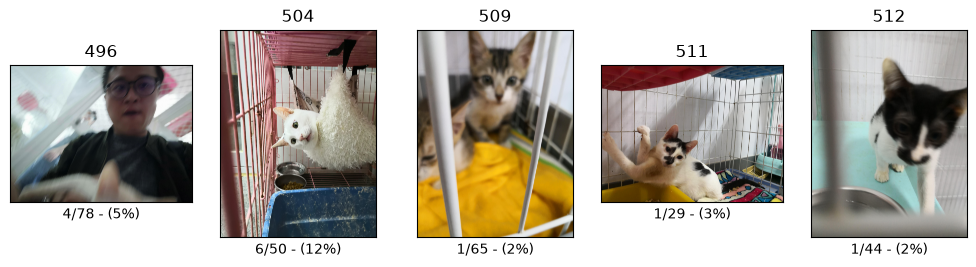

In [58]:
ids_undetected = df_analysis.loc[df_analysis['detected'] == 0, 'dir_name'].unique()
for i in range(0, len(ids_undetected), 10):
    clear_output(wait=True)
    ids_images = ids_undetected[i:i+10]

    plt.figure(figsize=(10, 5))
    for j, id in enumerate(ids_images):
        undetecteds_by_ids = df_analysis_undetected.loc[df_analysis_undetected['dir_name'] == id, ['file_path', 'dir_name']]
        total = len(df_reid_modified[df_reid_modified['dir_name'] == id])
        fallos = len(undetecteds_by_ids)
        path_image, id_image = undetecteds_by_ids.values[0]

        with Image.open(path_image) as img:
            plt.subplot(2, 5, j+1)
            plt.imshow(img)
            plt.title(id_image)
            plt.xlabel(f'{fallos}/{total} - ({fallos/total:.0%})')

            plt.xticks([])
            plt.yticks([])
            
    plt.tight_layout()
    plt.show()
    time.sleep(3)

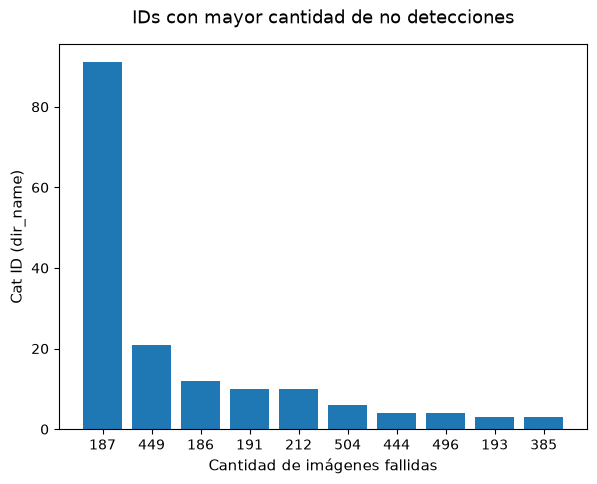

In [61]:
top_failures = df_analysis_undetected['dir_name'].value_counts().head(10)
list_top_failures = top_failures.index.tolist()

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.bar(top_failures.index.astype(str), top_failures.values, )

plt.title('IDs con mayor cantidad de no detecciones', fontsize=13, pad=15)
plt.xlabel('Cantidad de imágenes fallidas', fontsize=11)
plt.ylabel('Cat ID (dir_name)', fontsize=11)

plt.show()

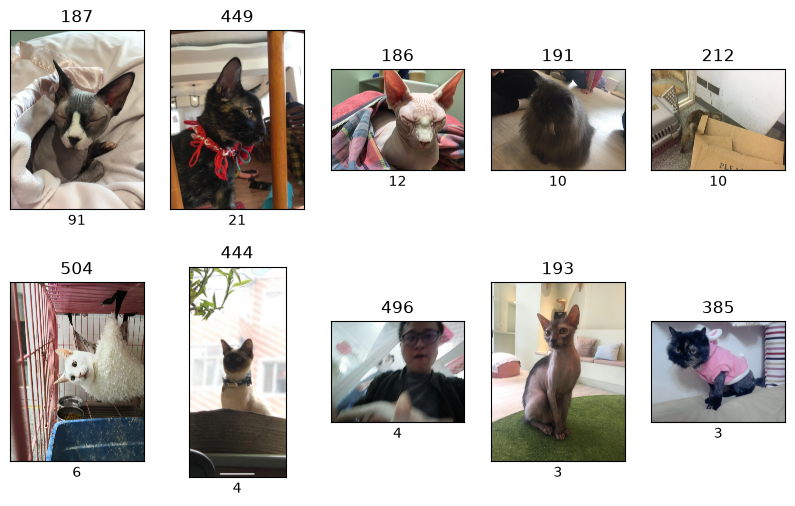

In [64]:
plt.figure(figsize=(10, 6))
for i, id in enumerate(list_top_failures):
    undetecteds_by_ids = df_analysis_undetected.loc[df_analysis_undetected['dir_name'] == id, ['file_path']]
    total_by_id = len(undetecteds_by_ids)
    path_image = undetecteds_by_ids.values[0][0]
    
    with Image.open(path_image) as img:
        plt.subplot(2, 5, i+1)
        plt.imshow(img)
        plt.title(id)
        plt.xlabel(total_by_id)
        plt.xticks([])
        plt.yticks([])
    